# Combining Techniques
This notebook will explore combining a few different techniques including:

- Time Stretching and Autotuning
- Magnitude Spectrum Manipulation
- Flat Magnitude Reconstruction and Concatenative Synthesis



In [1]:
pip install demucs

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.1/18.1 MB 59.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [demucs]


In [2]:
pip install psola

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.7/10.7 MB 66.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [psola]


# Time Stretching and Autotuning
I chose to use psola autotuning since I thought that the audio afterwards sounded more interesting.


In [3]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.signal as signal
import IPython.display as ipd
import librosa
import scipy.io.wavfile as wav
from scipy.io.wavfile import write
import psola
import scipy.signal as sig
import demucs.separate

# use this filename when working locally
filename = '/content/tomsdiner_mono.wav'
# use this filename when working within github
# filename = '../../data/tomsdiner_mono.wav'
srate, tomsdiner = wav.read(filename)

# Using Demucs, a source-separation model that can split a recording into vocals
# and instrumental accompaniment so that we can apply autotune to only the vocals

# in colab: creates two files: vocals.wav and no_vocals.wav
demucs.separate.main([
    "--two-stems=vocals",
    "-n", "htdemucs_ft",
    "-o", "/content",
    "/content/tomsdiner_stereo.wav"
])
# load the isolated vocals into librosa
vocals, srate = librosa.load(
    "/content/htdemucs_ft/tomsdiner_stereo/vocals.wav",
    sr=None,
    mono=True
)

instrumental, _ = librosa.load(
    "/content/htdemucs_ft/tomsdiner_stereo/no_vocals.wav",
    sr=srate,
    mono=True
)

# in github: creates two files: vocals.wav and no_vocals.wav
# demucs.separate.main([
#     "--two-stems=vocals",
#     "-n", "htdemucs_ft",
#     "-o", ".",
#     "../../data/tomsdiner_stereo.wav"
# ])

# # load the isolated vocals into librosa
# vocals, srate = librosa.load(
#     "./htdemucs_ft/tomsdiner_stereo/vocals.wav",
#     sr=None,
#     mono=True
# )

# instrumental, _ = librosa.load(
#     "./htdemucs_ft/tomsdiner_stereo/no_vocals.wav",
#     sr=srate,
#     mono=True
# )

htdemucs_ft.yaml:   0%|          | 0.00/149 [00:00<?, ?B/s]

f7e0c4bc.safetensors: reconstructing file:   0%|          |  0.00B / 84.0MB            

f7e0c4bc.safetensors: downloading bytes:           |  0.00B            

d12395a8.safetensors: reconstructing file:   0%|          |  0.00B / 84.0MB            

d12395a8.safetensors: downloading bytes:           |  0.00B            

92cfc3b6.safetensors: reconstructing file:   0%|          |  0.00B / 84.0MB            

92cfc3b6.safetensors: downloading bytes:           |  0.00B            

04573f0d.safetensors: reconstructing file:   0%|          |  0.00B / 84.0MB            

04573f0d.safetensors: downloading bytes:           |  0.00B            

Selected model is a bag of 4 models. You will see that many progress bars per track.
Separated tracks will be stored in /content/htdemucs_ft
Separating track /content/tomsdiner_stereo.wav


100%|██████████████████████████████████████████████████████████████████████████| 5.85/5.85 [00:21<00:00,  3.71s/seconds]
100%|██████████████████████████████████████████████████████████████████████████| 5.85/5.85 [00:13<00:00,  2.29s/seconds]
100%|██████████████████████████████████████████████████████████████████████████| 5.85/5.85 [00:13<00:00,  2.27s/seconds]
100%|██████████████████████████████████████████████████████████████████████████| 5.85/5.85 [00:12<00:00,  2.17s/seconds]


In [4]:
def save_audio_to_wav(filename, audio, srate=44100):
  """Saves an audio array as a wav file"""
  audio = audio / np.max(np.abs(audio))
  write(filename, srate, audio.astype(np.float32))

In [5]:
# listen to the original audio, then the isolated vocals to double check they sound right

# original unseparated audio
ipd.Audio(tomsdiner, rate=srate)

In [6]:
# vocals separated from audio
ipd.display(ipd.Audio(vocals, rate=srate))

In [7]:
# We can extract the pitch contour using the pyin fundamental frequency estimator from librosa

hopSize = 1024 # How many samples we move forward before analyzing the next frame
winSize = 4096 # How many audio samples are analyzed at once


# Monophonic pitch extraction using librosa.pyin: try with C3-C6 and C4-C6
f0, voiced_flag, voiced_probs = librosa.pyin(
  vocals,
  sr=srate,
  frame_length=winSize,
  hop_length=hopSize,
  fmin=librosa.note_to_hz('C2'),
  fmax=librosa.note_to_hz('C6'),
  center=False
)

# Apply a median filter to the estimated pitch track to remove sudden isolated errors in pitch estimation
f0 = signal.medfilt(f0, kernel_size=3)

offsets = np.arange(0, len(vocals)-winSize, hopSize)

# C Minor Pentatonic: C, Eb, F, G, Bb
minor_pentatonic = np.array([
    48, 51, 53, 55, 58,
    60, 63, 65, 67, 70,
    72
])

# C Whole Tone: C, D, E, F#, G#, A#
whole_tone = np.array([
    48, 50, 52, 54, 56, 58,
    60, 62, 64, 66, 68, 70,
    72
])

# C Phrygian: C, Db, Eb, F, G, Ab, Bb
phrygian = np.array([
    48, 49, 51, 53, 55, 56, 58,
    60, 61, 63, 65, 67, 68, 70,
    72
])

# Find the closest target pitch
def closest(m, scale):
    return scale[np.argmin(np.abs(scale-m))]

# AUTOTUNE
def autotune_psola(audio_signal, scale):
    fmin = librosa.note_to_hz('C2')
    fmax = librosa.note_to_hz('C7')
    mf0 = librosa.hz_to_midi(f0)
    corrected_f0 = [librosa.midi_to_hz(closest(mf, scale)) for mf in mf0]
    med_filtered = sig.medfilt(corrected_f0, kernel_size=3)
    output = psola.vocode(audio_signal, sample_rate=int(srate), target_pitch=med_filtered, fmin=fmin, fmax=fmax)
    return output

def autotune_and_mix(vocals, instrumental, scale, autotune_func):
    # Autotune the vocals using the chosen function and scale
    autotuned_vocals = autotune_func(vocals, scale)

    # Ensure both audio signals have the same length
    length = min(len(autotuned_vocals), len(instrumental))

    # Combine autotuned vocals with original instrumental
    final_audio = (
        autotuned_vocals[:length] +
        instrumental[:length]
    )

    # Prevent clipping - scale the amplitude according to the largest amplitude
    peak = np.max(np.abs(final_audio))
    if peak > 1:
        final_audio = final_audio / peak

    return final_audio

# TIME STRETCH
def phase_vocoder_time_stretch(audio, sample_rate, stretch_rate):
  # Convert to frequency domain
  D = librosa.stft(audio, n_fft=1024, hop_length=512)

  # Stretch the audio using the librosa phase_vocoder
  D_stretched = librosa.phase_vocoder(D, rate=stretch_rate, hop_length=512)

  # Reconstruct the audio back to time domain
  audio_stretched = librosa.istft(D_stretched, hop_length=512)

  return audio_stretched



We will try
- time stretching -> autotuning
- and autotuning -> time stretching

then we will compare the results

### 1 - Time Stretching -> Autotuning


In [8]:
ts_vocals_slow = phase_vocoder_time_stretch(vocals, srate, 0.85)
ts_instrumentals_slow = phase_vocoder_time_stretch(instrumental, srate, 0.85)

ts_vocals_fast = phase_vocoder_time_stretch(vocals, srate, 1.25)
ts_instrumentals_fast = phase_vocoder_time_stretch(instrumental, srate, 1.25)

whole_tone_vocals_slow = autotune_and_mix(ts_vocals_slow, ts_instrumentals_slow, whole_tone, autotune_psola)
whole_tone_vocals_fast = autotune_and_mix(ts_vocals_fast, ts_instrumentals_fast, whole_tone, autotune_psola)

minor_pentatonic_vocals_slow = autotune_and_mix(ts_vocals_slow, ts_instrumentals_slow, minor_pentatonic, autotune_psola)
minor_pentatonic_vocals_fast = autotune_and_mix(ts_vocals_fast, ts_instrumentals_fast, minor_pentatonic, autotune_psola)

phrygian_vocals_slow = autotune_and_mix(ts_vocals_slow, ts_instrumentals_slow, phrygian, autotune_psola)
phrygian_vocals_fast = autotune_and_mix(ts_vocals_fast, ts_instrumentals_fast, phrygian, autotune_psola)


In [10]:
save_audio_to_wav('audios/whole_tone_vocals_slow.wav', whole_tone_vocals_slow, srate)
ipd.Audio(whole_tone_vocals_slow, rate=srate)

In [11]:
save_audio_to_wav('audios/whole_tone_vocals_fast.wav', whole_tone_vocals_fast, srate)
ipd.Audio(whole_tone_vocals_fast, rate=srate)

In [12]:
save_audio_to_wav('audios/minor_pentatonic_vocals_slow.wav', minor_pentatonic_vocals_slow, srate)
ipd.Audio(minor_pentatonic_vocals_slow, rate=srate)

In [13]:
save_audio_to_wav('audios/minor_pentatonic_vocals_fast.wav', minor_pentatonic_vocals_fast, srate)
ipd.Audio(minor_pentatonic_vocals_fast, rate=srate)

In [14]:
save_audio_to_wav('audios/phrygian_vocals_slow.wav', phrygian_vocals_slow, srate)
ipd.Audio(phrygian_vocals_slow, rate=srate)

In [15]:
save_audio_to_wav('audios/phrygian_vocals_fast.wav', phrygian_vocals_fast, srate)
ipd.Audio(phrygian_vocals_fast, rate=srate)

### 2 - Autotuning -> Time Stretching
After experimenting with the order, the difference is barely noticeable in the audios, so we will not focus on the order too much.

In [ ]:
# whole_tone_audio = autotune_and_mix(vocals, instrumental, whole_tone, autotune_psola)
# minor_pentatonic_audio = autotune_and_mix(vocals, instrumental, minor_pentatonic, autotune_psola)
# phrygian_audio = autotune_and_mix(vocals, instrumental, phrygian, autotune_psola)

# whole_tone_vocals_slow = phase_vocoder_time_stretch(whole_tone_audio, srate, 0.85)
# whole_tone_vocals_fast = phase_vocoder_time_stretch(whole_tone_audio, srate, 1.25)

In [ ]:
# ipd.Audio(whole_tone_vocals_slow, rate=srate)

In [ ]:
# ipd.Audio(whole_tone_vocals_fast, rate=srate)

##Now lets try to make a new melody both psola autotuning and time stretching!
Since I have very little musical knowledge I got some help from AI to do this, the result is not anything special, but this is a good framework for remixing the vocals of the song after autotuning and time stretching.


In [16]:
# REMIX: Autotuned vocals + instrumental backing

def chop(audio, start, end):
    return audio[int(start*srate):int(end*srate)]

def process(audio, rate, scale):
    global f0

    audio = phase_vocoder_time_stretch(audio, srate, rate)

    # Recalculate f0 for the stretched audio
    f0, _, _ = librosa.pyin(
        audio, sr=srate,
        frame_length=4096,
        hop_length=1024,
        fmin=librosa.note_to_hz('C2'),
        fmax=librosa.note_to_hz('C6'),
        center=False
    )

    # fill unvoiced frames for the existing autotune function
    valid = np.isfinite(f0)
    if valid.any():
        # np.interp performs linear interpolation, estimating missing values based on the
        # known values around them
        f0 = np.interp(np.arange(len(f0)),
                       np.flatnonzero(valid), f0[valid])
        audio = autotune_psola(audio, scale)

    return audio

# Create different vocal fragments
a = process(chop(vocals, 0.0, 1.2), 0.85, whole_tone)
b = process(chop(vocals, 1.2, 2.1), 1.25, minor_pentatonic)
c = process(chop(vocals, 2.1, 3.3), 0.75, phrygian)
d = process(chop(vocals, 3.3, 4.5), 1.15, whole_tone)

# Create a 10-second remix
duration = 10
n = int(duration * srate)

# Repeat instrumental to cover the remix
backing = np.tile(instrumental, int(np.ceil(n / len(instrumental))))[:n]
remix = 0.55 * backing

# Add vocal chops at specific times
def add_vocal(audio, start, volume=0.8):
    global remix

    audio = audio.copy()

    # Short fades for smoother transitions
    fade = min(int(0.03*srate), len(audio)//2)
    audio[:fade] *= np.linspace(0, 1, fade)
    audio[-fade:] *= np.linspace(1, 0, fade)

    start_sample = int(start*srate)
    end_sample = min(start_sample + len(audio), len(remix))

    if end_sample > start_sample:
        remix[start_sample:end_sample] += (
            volume * audio[:end_sample-start_sample]
        )

# Arrange the vocal remix
add_vocal(a, 0.0)
add_vocal(b, 1.5)
add_vocal(b, 2.3, 0.65)
add_vocal(c, 3.2)
add_vocal(d, 4.9)
add_vocal(a, 5.8)
add_vocal(b, 7.2)
add_vocal(d, 8.0)
add_vocal(c, 8.7)

# Fade instrumental in and out
fade = int(0.2*srate)
remix[:fade] *= np.linspace(0, 1, fade)
remix[-fade:] *= np.linspace(1, 0, fade)

# Normalize
remix = remix / max(np.max(np.abs(remix)), 1e-10) * 0.9

# Listen
ipd.display(ipd.Audio(remix, rate=srate))

# Save
save_audio_to_wav('audios/psola_and_timestretch_remix.wav', remix, srate)


(End of Time Stretching and Autotuning Section)


------
-------
--------
------
-------
--------
------
-------
--------
------
-------
--------
------
-------




-------
-------
-------
-------


<br/>
<br/>


# Magnitude Spectrum Manipulation + Reverb
More information about individual techniques in their respective notebooks in the repo. From this point on, we will experiment with combining crude filtering and reverb.

<br/>

### Observations (see audio and plots generated)
<br/>

**AUDIO FROM FILTERING FIRST**

This definitely had a more interesting effect, the sound produced sounded more "noisy", almost as if listening to it in an underground tunnel or like it's music from a concert that is far away, especially for the low filtered reverb.

In the RMS Amplitude plot we can see that filtering first produces a more gradual decay from the reverb and that the amplitude trends higher except at certain peaks.

<br/>


**AUDIO FROM REVERB FIRST**

The effects of the filtering had a less drastic effect on the overall sound produced, the original pitch was preserved a lot better too.

In the RMS Amplitude plot we can see that reverbing first reduces the amplitude faster at the end. In the Spectral Centroid plot we can see that reverbing first that there is much brighter sound at the end even though that is when the song is supposed to be getting quieter, probably because the measurements of frequency get more unreliable as they approach zero/silence.

In [17]:
# additional imports needed for the next techniques
from scipy.signal import lfilter
import soundfile as sf
import scipy.fft as fft

# CRUDE FILTERING CODE FROM Magnitude_Spectrum_Manipulation.ipynb
def crude_filtering(signal: np.ndarray, frequency_range: tuple[float, float]) -> np.ndarray:
  complex_spectrum = fft.rfft(signal)
  magnitude_spectrum = np.abs(complex_spectrum)

  num_bins = len(magnitude_spectrum)
  start = (frequency_range[0] * num_bins)
  end = (frequency_range[1] * num_bins)

  magnitude_spectrum[int(start):int(end)] = 0.0
  phase_spectrum = np.angle(complex_spectrum)
  reconstructed_complex_spectrum = magnitude_spectrum * (np.cos(phase_spectrum)+1j*np.sin(phase_spectrum))

  reconstructed_signal = fft.irfft(reconstructed_complex_spectrum)

  return reconstructed_signal


def band_pass_crude_filtering(signal: np.ndarray, frequency_range: tuple[float, float]) -> np.ndarray:
  lower_frequency_range = (0.0, frequency_range[0])
  upper_frequency_range = (frequency_range[1], 1.0)

  # filter out the frequencies in the lower frequency range
  lower_filtered_signal = crude_filtering(signal, lower_frequency_range)
  # filter out the freqs in the upper range of the lower_filtered_signal so that
  # final signal contains both ranges filtered out
  band_pass_filtered_signal = crude_filtering(lower_filtered_signal, upper_frequency_range)

  return band_pass_filtered_signal

low_pass = (0.10, 1.00)
high_pass = (0.0, 0.35)
band_stop = (0.250, 0.75)
band_pass = (0.20, 0.70)

# FREEVERB IMPLEMENTATION FROM reverb.ipynb
def _rms(a):
    return np.sqrt(np.mean(np.asarray(a) ** 2)) + 1e-12

def _damped_comb(x, delay, rt60, damp, sr):
    fb = 10.0 ** (-3.0 * delay / (sr * rt60))
    a = np.zeros(delay + 2)
    a[0], a[1] = 1.0, -damp
    a[delay] -= fb * (1 - damp)
    b = np.zeros(delay + 2)
    b[delay], b[delay + 1] = 1.0, -damp
    return lfilter(b, a, x)


def _allpass(x, delay, g=0.5):
    b = np.zeros(delay + 1)
    a = np.zeros(delay + 1)
    b[0], b[delay] = -g, 1.0
    a[0], a[delay] = 1.0, -g
    return lfilter(b, a, x)

def _finish(x, wet, sr, mix, predelay):
    n_out = len(wet)
    if predelay > 0:
        pd = int(predelay * sr)
        wet = np.vstack([np.zeros((pd, 2)), wet])[:n_out]
    wet = wet * (_rms(x) / _rms(wet[:len(x)]))
    dry = np.zeros(n_out)
    dry[:len(x)] = x
    m = np.asarray(mix, float)
    if m.ndim:
        m = np.interp(np.linspace(0, 1, n_out), np.linspace(0, 1, len(m)), m)
        m = m[:, None]
    return (1 - m) * dry[:, None] + m * wet

# Freeverb implementation (https://ccrma.stanford.edu/~jos/pasp/Freeverb.html)
def freeverb(x, sr, decay=2.0, damp=0.3, mix=0.3, predelay=0.0, tail=None, spread=23):
    s = sr / 44100
    tail_n = int((decay if tail is None else tail) * sr)
    xp = np.concatenate([x, np.zeros(tail_n)])
    wet = np.zeros((len(xp), 2))
    comb = [1116, 1188, 1277, 1356, 1422, 1491, 1557, 1617]
    ap = [556, 441, 341, 225]
    for ch in range(2):
        off = ch * int(spread * s)
        acc = sum(_damped_comb(xp, int(d * s) + off, decay, damp, sr) for d in comb)
        for d in ap:
            acc = _allpass(acc, int(d * s) + off)
        wet[:, ch] = acc
    return np.transpose(_finish(x, wet, sr, mix, predelay))



### Try: filtering -> apply reverb

Filtering first changes the sound that gets given to the reverb algorithm whereas filtering afterward removes some frequencies from the reverbed audio, so the tone will likely change depending on the order in which these techniques are applied.

In [18]:
# Applying crude filters
low_filtered = crude_filtering(tomsdiner, low_pass)
high_filtered = crude_filtering(tomsdiner, high_pass)
band_filtered = band_pass_crude_filtering(tomsdiner, band_pass)

# Apply reverb to each filtered signal
low_reverb = freeverb(low_filtered, srate, decay=3.0, mix=0.5)
high_reverb = freeverb(high_filtered, srate, decay=2.0, mix=0.5)
band_reverb = freeverb(band_filtered, srate, decay=4.0, mix=0.6)


In [19]:
# Sounds like walking away from a music festival or a tunnel where someone is blasting music
save_audio_to_wav('audios/low_filtered_then_reverb.wav', low_reverb.T)
ipd.Audio(low_reverb, rate=srate)

In [20]:
# Still sounds like marracas (in crude filtering exploration it also sounded essentially the same)
save_audio_to_wav('audios/high_filtered_then_reverb.wav', high_reverb.T)
ipd.Audio(high_reverb, rate=srate)

In [21]:
# sounds like when you can hear sound coming out of someone elses headphones and
# you're worried for their ear health
save_audio_to_wav('audios/band_filtered_then_reverb.wav', band_reverb.T)
ipd.Audio(band_reverb, rate=srate)

### try: reverb first -> filtering

In [22]:
# make sure decay and mix rate are the same for both orders of operation to accurately
# see the differences based on order (not caused by differing decay/mix input)

# Reverb First -> Low Filtering
reverb_first = freeverb(tomsdiner, srate, decay=3.0, mix=0.5)

# Have to filter the left and right channels separately
reverb_first_low_filtered = np.array([
    crude_filtering(channel, low_pass)
    for channel in reverb_first
])

# Reverb First -> High Filtering
reverb_first = freeverb(tomsdiner, srate, decay=2.0, mix=0.5)

reverb_first_high_filtered = np.array([
    crude_filtering(channel, high_pass)
    for channel in reverb_first
])

# Reverb First -> Band Filtering
reverb_first = freeverb(tomsdiner, srate, decay=4.0, mix=0.6)
reverb_first_band_filtered = np.array([
    band_pass_crude_filtering(channel, band_pass)
    for channel in reverb_first
])

In [23]:
save_audio_to_wav('audios/reverb_first_low_filtered.wav', reverb_first_low_filtered.T)
ipd.Audio(reverb_first_low_filtered, rate=srate)

In [24]:
save_audio_to_wav('audios/reverb_first_high_filtered.wav', reverb_first_high_filtered.T)
ipd.Audio(reverb_first_high_filtered, rate=srate)

In [25]:
save_audio_to_wav('audios/reverb_first_band_filtered.wav', reverb_first_band_filtered.T)
ipd.Audio(reverb_first_band_filtered, rate=srate)

# Plots

- **RMS plot:** shows the differences in amplitude indicating how the order of reverb/filtering affects the signal's energy
- **Spectral centroid plot:** higher values = more energy concentrated at higher frequencies and lower values = more muffled sounds


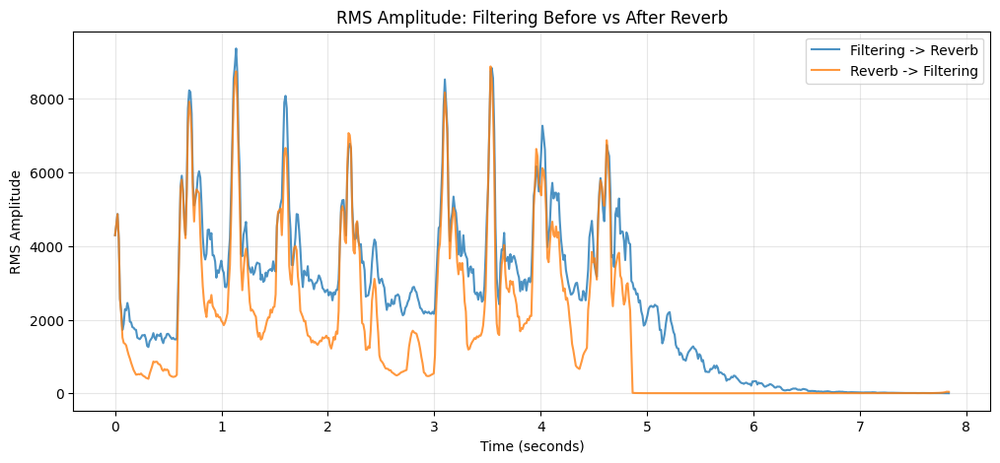

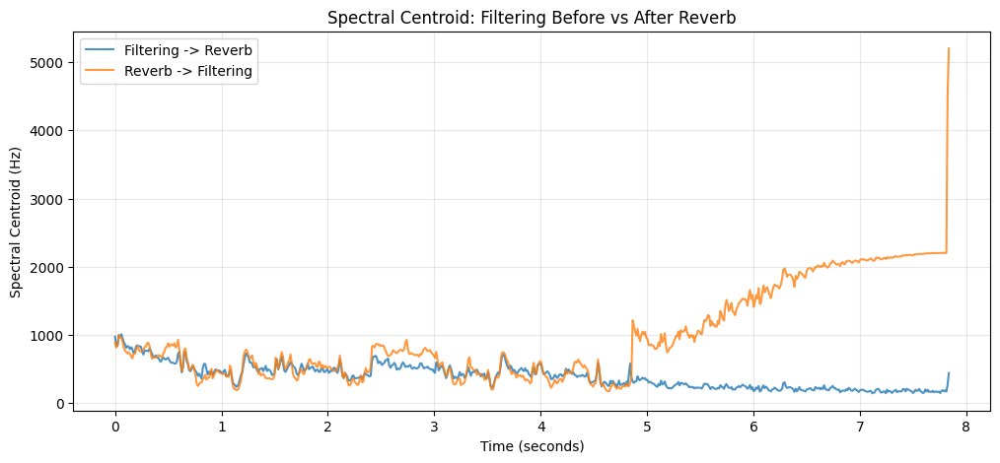

In [26]:
# Convert stereo (channels, samples) to mono for analysis
filter_first = np.mean(low_reverb, axis=0)
reverb_first = np.mean(reverb_first_low_filtered, axis=0)

signals = {
    "Filtering -> Reverb": filter_first,
    "Reverb -> Filtering": reverb_first
}

# PLOT 1: RMS amplitude over time
plt.figure(figsize=(12, 5))

for label, audio in signals.items():
    rms = librosa.feature.rms(y=audio, frame_length=2048,
                             hop_length=512)[0]
    times = librosa.times_like(rms, sr=srate, hop_length=512)

    plt.plot(times, rms, label=label, alpha=0.8)

plt.xlabel("Time (seconds)")
plt.ylabel("RMS Amplitude")
plt.title("RMS Amplitude: Filtering Before vs After Reverb")
plt.legend()
plt.grid(alpha=0.3)

plt.savefig("plots/filter_reverb_rms.png",
            dpi=300, bbox_inches="tight")
plt.show()


# PLOT 2: Spectral centroid over time
plt.figure(figsize=(12, 5))

for label, audio in signals.items():
    centroid = librosa.feature.spectral_centroid(
        y=audio, sr=srate, n_fft=2048, hop_length=512
    )[0]

    times = librosa.times_like(centroid, sr=srate, hop_length=512)

    plt.plot(times, centroid, label=label, alpha=0.8)

plt.xlabel("Time (seconds)")
plt.ylabel("Spectral Centroid (Hz)")
plt.title("Spectral Centroid: Filtering Before vs After Reverb")
plt.legend()
plt.grid(alpha=0.3)

plt.savefig("plots/filter_reverb_centroid.png",
            dpi=300, bbox_inches="tight")
plt.show()

(end of Magnitude Spectrum Manipulation + Reverb)

-------
-------
-------
-------
-------
-------
-------
-------


-------
-------
-------
-------
# Combination of Flat Magnitude Reconstruction, Magnitude Spectrum Manipulation, Autotune, and Time Stretching to make an experimental remix

Play the following in a sequence
1. audio with FMR + low pass crude filtering + slowed
2. vocals PSOLA autotuned
3. vocals with autotune + audio band pass filtering + audio time stretching sped up
4. vocals with autotune + flat magnitude reconstruction + low pass + time stretching slowed
5. Original toms diner

In [27]:
def flat_magnitude_reconstruct(signal: np.ndarray, amplitude: float) -> np.ndarray:
  if (amplitude < 0.0) or (amplitude > 1.0):
    raise ValueError('Amplitude must be between 0.0 and 1.0')

  complex_spectrum = fft.rfft(signal)

  magnitude_spectrum = np.full(len(complex_spectrum), amplitude)

  phase_spectrum = np.angle(complex_spectrum)

  reconstructed_complex_spectrum = magnitude_spectrum *(np.cos(phase_spectrum) + 1j*np.sin(phase_spectrum))
  reconstructed_signal = fft.irfft(reconstructed_complex_spectrum)

  return reconstructed_signal


In [28]:
# 1 - FMR + low pass crude filtering + slowed

# flatten the magnitude
flat_toms_diner = flat_magnitude_reconstruct(tomsdiner, 1)


# low pass crude filtering on the flattened audio
fmr_low_pass_toms_diner = crude_filtering(flat_toms_diner, low_pass)

# time stretch
slowed_fmr_low_pass_toms_diner = phase_vocoder_time_stretch(fmr_low_pass_toms_diner, srate, 0.5)


In [38]:
save_audio_to_wav('audios/flat_toms_diner.wav', slowed_fmr_low_pass_toms_diner)
ipd.Audio(flat_toms_diner, rate=srate)


In [39]:
save_audio_to_wav('audios/fmr_low_pass_toms_diner.wav', fmr_low_pass_toms_diner)
ipd.Audio(fmr_low_pass_toms_diner, rate=srate)

In [40]:
save_audio_to_wav('audios/slowed_fmr_low_pass_toms_diner.wav', slowed_fmr_low_pass_toms_diner)
ipd.Audio(slowed_fmr_low_pass_toms_diner, rate=srate)

In [41]:
# 2 - Autotuned with Phrygian scale
toms_diner_psola_phrygian = autotune_and_mix(vocals, instrumental, phrygian, autotune_psola)

save_audio_to_wav('audios/toms_diner_psola_phrygian.wav', toms_diner_psola_phrygian)
ipd.Audio(toms_diner_psola_phrygian, rate=srate)

In [42]:
# 3 - Autotune + band-pass + sped up
band_pass = (0.3,0.6)
toms_diner_auto_band_pass = band_pass_crude_filtering(toms_diner_psola_phrygian, band_pass)

save_audio_to_wav('audios/toms_diner_auto_band_pass.wav', toms_diner_auto_band_pass)
ipd.Audio(toms_diner_auto_band_pass, rate=srate)

In [43]:
toms_diner_auto_band_pass_sped_up = phase_vocoder_time_stretch(toms_diner_auto_band_pass, srate, 1.5)
save_audio_to_wav('audios/toms_diner_auto_band_pass_sped_up.wav', toms_diner_auto_band_pass_sped_up)
ipd.Audio(toms_diner_auto_band_pass_sped_up, rate=srate)

In [44]:
# 4 - Autotune + FMR + low pass + slow

fmr_toms_diner_autotune = flat_magnitude_reconstruct(toms_diner_psola_phrygian, 1.0)

save_audio_to_wav('audios/fmr_toms_diner_autotune.wav', fmr_toms_diner_autotune)
ipd.Audio(fmr_toms_diner_autotune, rate=srate)


In [45]:
fmr_autotune_low_pass_td = crude_filtering(fmr_toms_diner_autotune, low_pass)
save_audio_to_wav('audios/fmr_autotune_low_pass_td.wav', fmr_autotune_low_pass_td)
ipd.Audio(fmr_autotune_low_pass_td, rate=srate)

In [46]:
fmr_autotune_low_pass_slow_td = phase_vocoder_time_stretch(fmr_autotune_low_pass_td, srate, 0.5)
save_audio_to_wav('audios/fmr_autotune_low_pass_slow_td.wav', fmr_autotune_low_pass_slow_td)
ipd.Audio(fmr_autotune_low_pass_slow_td, rate=srate)

In [51]:
# Remix
# Set the duration of each clip in seconds
clip_duration = 3

# Extract 5 seconds from each audio signal
clip1 = slowed_fmr_low_pass_toms_diner[:int(clip_duration * srate)]
clip2 = toms_diner_psola_phrygian[:int(clip_duration * srate)]
clip3 = toms_diner_auto_band_pass_sped_up[:int(clip_duration * srate)]
clip4 = fmr_autotune_low_pass_slow_td[:int(clip_duration * srate)]
clip5 = tomsdiner[:int(clip_duration * srate)]

def normalize_audio(audio):
    max_amp = np.max(np.abs(audio))
    if max_amp > 0:
        return audio / max_amp
    return audio

remix = np.concatenate([
    normalize_audio(clip1),
    normalize_audio(clip2),
    normalize_audio(clip2),
    normalize_audio(clip4),
    normalize_audio(clip5)
])

# Repeat clip 3 to match the length of the remix so that it can play in the background like percussion
background = np.tile(
    normalize_audio(clip3),
    int(np.ceil(len(remix) / len(clip3)))
)

# Trim background to exactly match remix length
background = background[:len(remix)]

# Mix clip 3 into the background at a lower volume
remix = remix * 0.8 + background * 0.4

# Save and play the remix
save_audio_to_wav('audios/toms_diner_combo_remix.wav', remix)
ipd.display(ipd.Audio(remix, rate=srate))
